In [1]:
import os
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("CPU cores:", os.cpu_count())

GPU Available: False
CPU cores: 2


In [3]:
!pip install jedi "decorator>=4.0.2,<5.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 29.8 MB/s  0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 5.3.1
    Uninstalling decorator-5.3.1:
      Successfully uninstalled decorator-5.3.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [decorator]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mne 1.13.2 requires decorator>=5.1, but you have decorator 4.4.2 which is incompatible.


In [1]:
import mne
import numpy as np
import scipy
import pandas as pd
import sklearn
import torch

print("MNE:", mne.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)

print("\nAll core SleepSense libraries imported successfully!")

MNE: 1.13.2
NumPy: 2.1.3
SciPy: 1.16.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
PyTorch: 2.11.0+cpu

All core SleepSense libraries imported successfully!


In [2]:
!pip check

mne 1.13.2 has requirement decorator>=5.1, but you have decorator 4.4.2.


In [3]:
%pip install -q --upgrade "decorator>=5.1"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [4]:
import mne
import numpy as np
import scipy
import pandas as pd
import sklearn
import torch
import decorator

print("MNE:", mne.__version__)
print("Decorator:", decorator.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)

print("\nSleepSense core libraries imported successfully!")

MNE: 1.13.2
Decorator: 4.4.2
NumPy: 2.1.3
SciPy: 1.16.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
PyTorch: 2.11.0+cpu

SleepSense core libraries imported successfully!


In [5]:
import os

DATA_PATH = "/content/sleepsense/data"
os.makedirs(DATA_PATH, exist_ok=True)

base_url = "https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette"

!wget -c -P /content/sleepsense/data https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette/SC4001E0-PSG.edf

!wget -c -P /content/sleepsense/data https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette/SC4001EC-Hypnogram.edf

--2026-10-30 03:02:28--  https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette/SC4001E0-PSG.edf
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://physionet-open.s3.amazonaws.com/sleep-edfx/1.0.0/sleep-cassette/SC4001E0-PSG.edf [following]
--2026-10-30 03:02:30--  https://physionet-open.s3.amazonaws.com/sleep-edfx/1.0.0/sleep-cassette/SC4001E0-PSG.edf
Resolving physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)... 16.15.156.170, 16.182.96.34, 16.15.253.152, ...
Connecting to physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)|16.15.156.170|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 48338048 (46M) [binary/octet-stream]
Saving to: ‘/content/sleepsense/data/SC4001E0-PSG.edf’

SC4001E0-PSG.edf    100%[===================>]  46.10M  31.2MB/s    in 1.5s    

2026-10-30 03:02:32 (31.

In [6]:
import mne

psg_path = f"{DATA_PATH}/SC4001E0-PSG.edf"

raw = mne.io.read_raw_edf(
    psg_path,
    preload=True,
    verbose=False
)

print(raw)

/tmp/ipykernel_2557/465606358.py:5: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_2557/465606358.py:5: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_2557/465606358.py:5: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(


<RawEDF | SC4001E0-PSG.edf, 7 x 7950000 (79500.0 s), ~424.6 MiB, data loaded>


In [7]:
print("Recording information")
print("----------------------")

print("Channels:", raw.ch_names)
print("Number of channels:", len(raw.ch_names))
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Duration:", round(raw.times[-1] / 3600, 2), "hours")
print("Number of samples:", raw.n_times)

Recording information
----------------------
Channels: ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']
Number of channels: 7
Sampling frequency: 100.0 Hz
Duration: 22.08 hours
Number of samples: 7950000


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


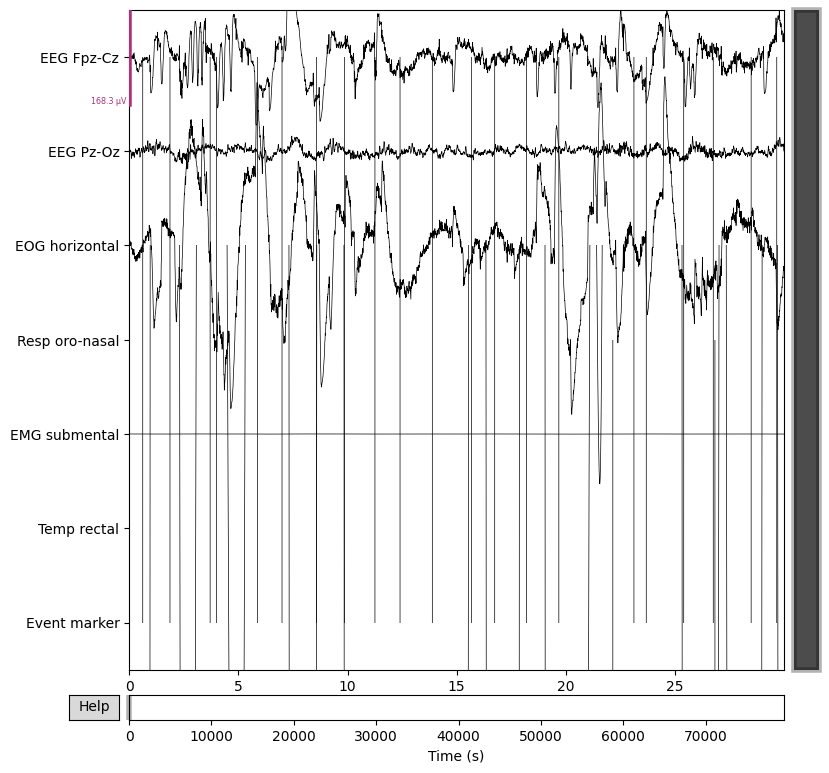

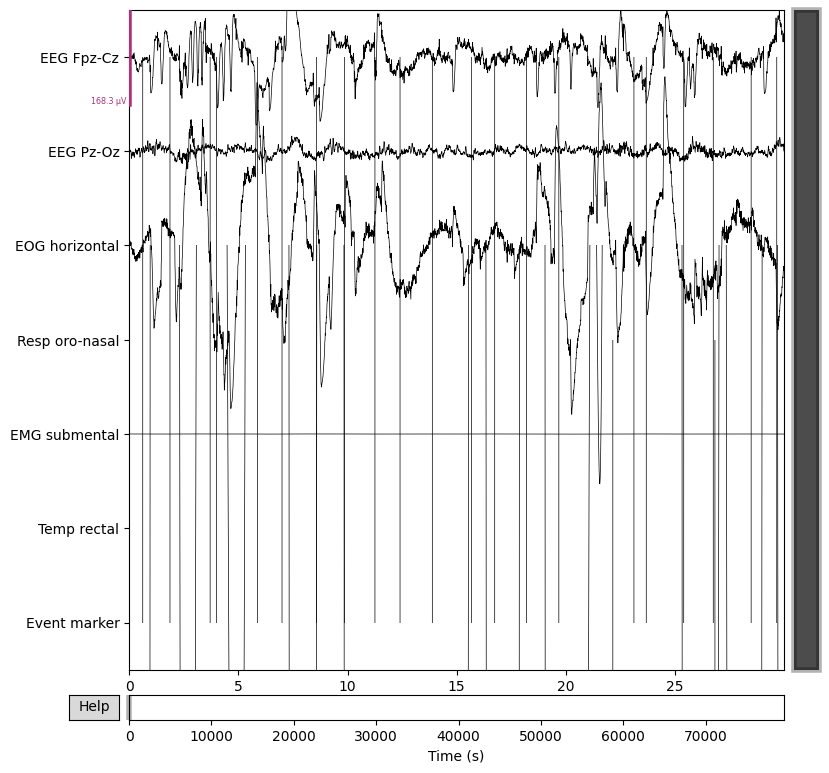

In [8]:
raw.plot(
    duration=30,
    n_channels=10,
    scalings="auto"
)

In [9]:
hyp_path = f"{DATA_PATH}/SC4001EC-Hypnogram.edf"

annotations = mne.read_annotations(hyp_path)

print("Number of annotations:", len(annotations))

for i in range(min(15, len(annotations))):
    print(
        annotations.onset[i],
        annotations.duration[i],
        annotations.description[i]
    )

Number of annotations: 154
0.0 30630.0 Sleep stage W
30630.0 120.0 Sleep stage 1
30750.0 390.0 Sleep stage 2
31140.0 30.0 Sleep stage 3
31170.0 30.0 Sleep stage 2
31200.0 150.0 Sleep stage 3
31350.0 30.0 Sleep stage 4
31380.0 60.0 Sleep stage 3
31440.0 60.0 Sleep stage 4
31500.0 30.0 Sleep stage 3
31530.0 120.0 Sleep stage 4
31650.0 30.0 Sleep stage 3
31680.0 120.0 Sleep stage 4
31800.0 30.0 Sleep stage W
31830.0 60.0 Sleep stage 3


In [10]:
print("Available channels:")

for i, channel in enumerate(raw.ch_names):
    print(i, channel)

Available channels:
0 EEG Fpz-Cz
1 EEG Pz-Oz
2 EOG horizontal
3 Resp oro-nasal
4 EMG submental
5 Temp rectal
6 Event marker


In [11]:
eeg_channels = [
    ch for ch in raw.ch_names
    if "EEG" in ch.upper()
]

print("EEG channels:", eeg_channels)

EEG channels: ['EEG Fpz-Cz', 'EEG Pz-Oz']


In [12]:
eeg_raw = raw.copy().pick(eeg_channels)

print(eeg_raw)
print("\nEEG sampling frequency:",
      eeg_raw.info["sfreq"], "Hz")

<RawEDF | SC4001E0-PSG.edf, 2 x 7950000 (79500.0 s), ~121.3 MiB, data loaded>

EEG sampling frequency: 100.0 Hz


In [13]:
import numpy as np

eeg_data = eeg_raw.get_data()

print("Signal shape:", eeg_data.shape)
print("Minimum amplitude (µV):",
      round(eeg_data.min() * 1e6, 2))
print("Maximum amplitude (µV):",
      round(eeg_data.max() * 1e6, 2))
print("Mean amplitude (µV):",
      round(eeg_data.mean() * 1e6, 2))

Signal shape: (2, 7950000)
Minimum amplitude (µV): -192.0
Maximum amplitude (µV): 196.0
Mean amplitude (µV): -0.09


In [14]:
filtered_eeg = eeg_raw.copy()

filtered_eeg.filter(
    l_freq=0.3,
    h_freq=35.0,
    method="fir",
    verbose=False
)

print("Filtering completed!")

Filtering completed!


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


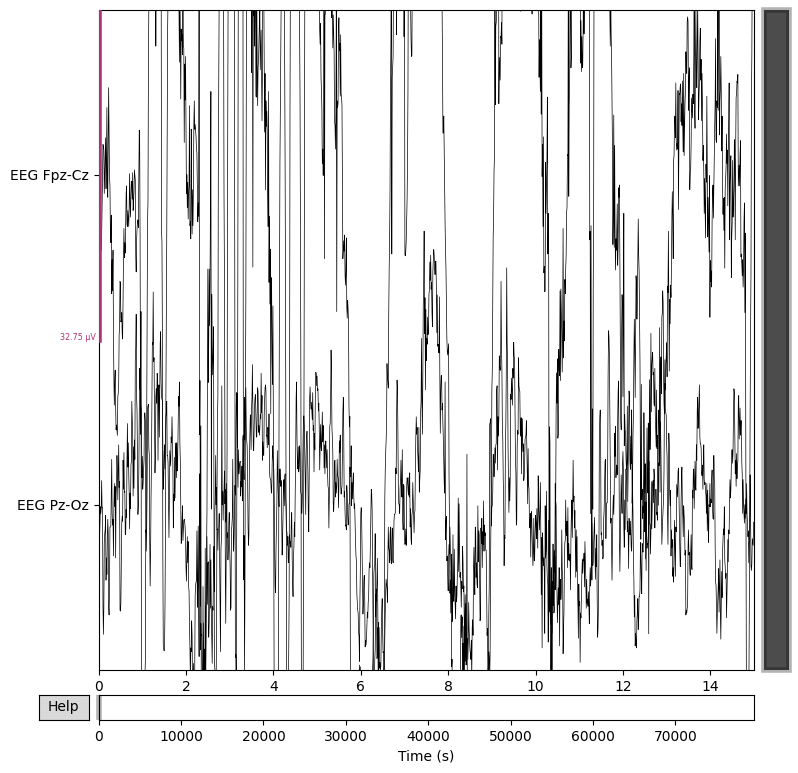

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


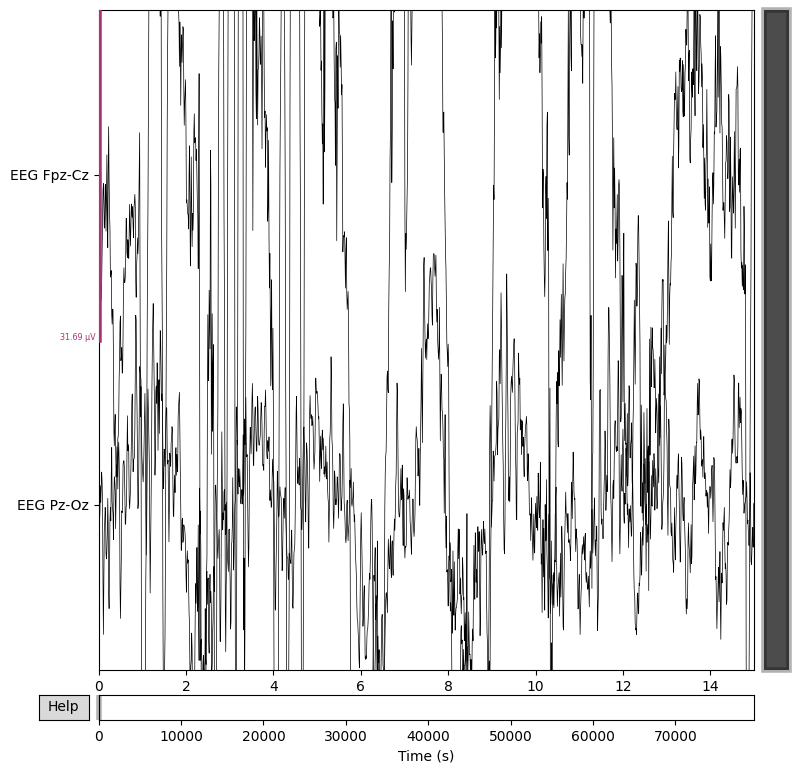

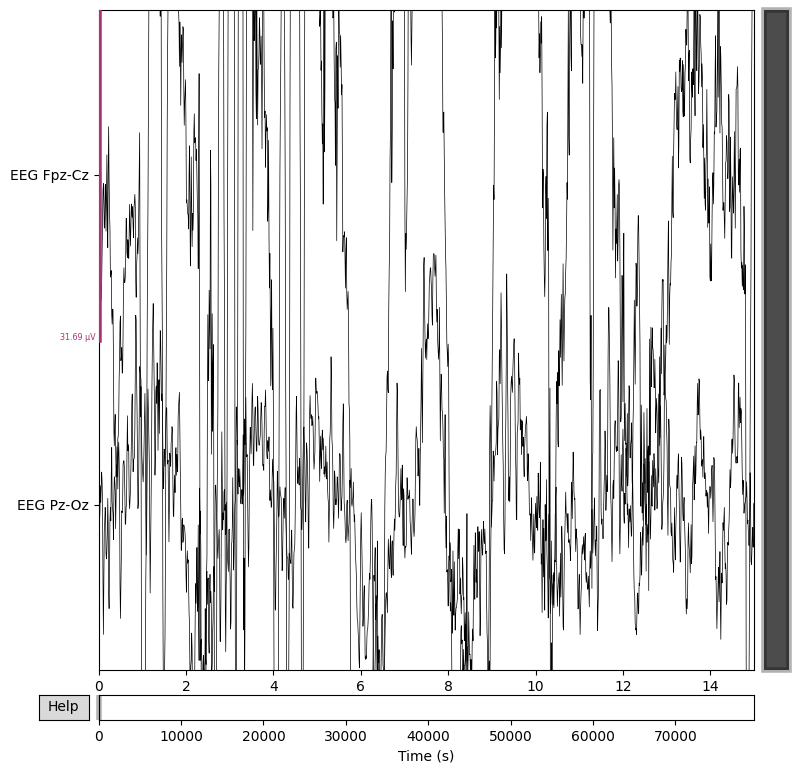

In [15]:
# Original EEG
eeg_raw.plot(
    duration=15,
    n_channels=len(eeg_channels),
    scalings="auto",
    title="Original EEG"
)

# Filtered EEG
filtered_eeg.plot(
    duration=15,
    n_channels=len(eeg_channels),
    scalings="auto",
    title="Filtered EEG"
)

Effective window size : 20.480 (s)
Plotting power spectral density (dB=True).


/tmp/ipykernel_2557/3874606256.py:5: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  ).plot()


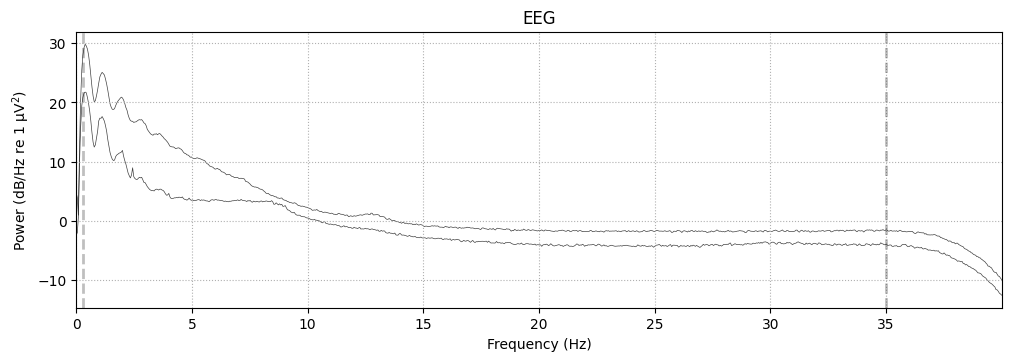

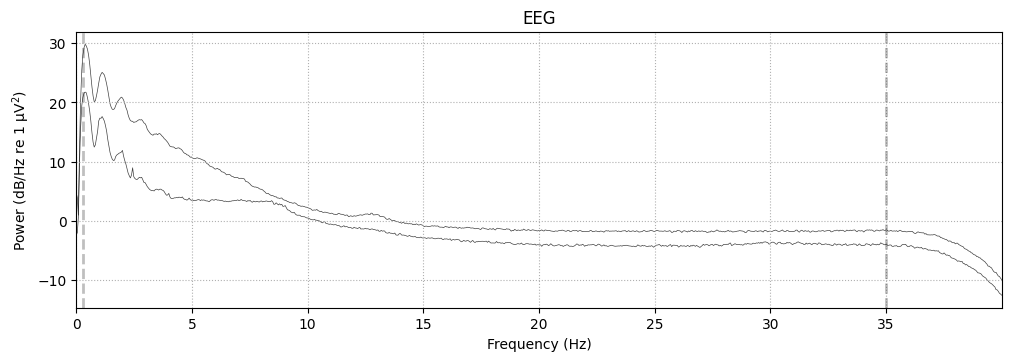

In [16]:
filtered_eeg.compute_psd(
    method="welch",
    fmin=0,
    fmax=40
).plot()

In [17]:
from collections import Counter

print(Counter(annotations.description))

Counter({'Sleep stage 3': 48, 'Sleep stage 2': 40, 'Sleep stage 1': 24, 'Sleep stage 4': 23, 'Sleep stage W': 12, 'Sleep stage R': 6, 'Sleep stage ?': 1})


In [18]:
stage_mapping = {
    "Sleep stage W": "W",
    "Sleep stage 1": "N1",
    "Sleep stage 2": "N2",
    "Sleep stage 3": "N3",
    "Sleep stage 4": "N3",
    "Sleep stage R": "REM"
}

print(stage_mapping)

{'Sleep stage W': 'W', 'Sleep stage 1': 'N1', 'Sleep stage 2': 'N2', 'Sleep stage 3': 'N3', 'Sleep stage 4': 'N3', 'Sleep stage R': 'REM'}


In [19]:
filtered_eeg.set_annotations(annotations)

print("Annotations attached:", len(filtered_eeg.annotations))

Annotations attached: 154


/tmp/ipykernel_2557/1930306033.py:1: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  filtered_eeg.set_annotations(annotations)


In [20]:
event_id = {
    description: i + 1
    for i, description in enumerate(stage_mapping.keys())
}

events, event_mapping = mne.events_from_annotations(
    filtered_eeg,
    event_id=event_id,
    chunk_duration=30.0,
    verbose=False
)

print("Event mapping:", event_mapping)
print("Total 30-second events:", len(events))

Event mapping: {'Sleep stage 1': 2, 'Sleep stage 2': 3, 'Sleep stage 3': 4, 'Sleep stage 4': 5, 'Sleep stage R': 6, 'Sleep stage W': 1}
Total 30-second events: 2650


In [21]:
sfreq = filtered_eeg.info["sfreq"]

epochs = mne.Epochs(
    filtered_eeg,
    events,
    event_id=event_id,
    tmin=0,
    tmax=30 - 1/sfreq,
    baseline=None,
    preload=True,
    reject_by_annotation=True,
    verbose=False
)

print(epochs)
print("Epoch data shape:", epochs.get_data().shape)

<Epochs | 2650 events (all good), 0 – 29.99 s (baseline off), ~121.3 MiB, data loaded,
 'Sleep stage W': 1997
 'Sleep stage 1': 58
 'Sleep stage 2': 250
 'Sleep stage 3': 101
 'Sleep stage 4': 119
 'Sleep stage R': 125>
Epoch data shape: (2650, 2, 3000)


In [22]:
code_to_stage = {
    event_id[description]: stage
    for description, stage in stage_mapping.items()
}

y = [
    code_to_stage[code]
    for code in epochs.events[:, 2]
]

print("Total labelled epochs:", len(y))
print("Sleep-stage distribution:")
print(Counter(y))

Total labelled epochs: 2650
Sleep-stage distribution:
Counter({'W': 1997, 'N2': 250, 'N3': 220, 'REM': 125, 'N1': 58})


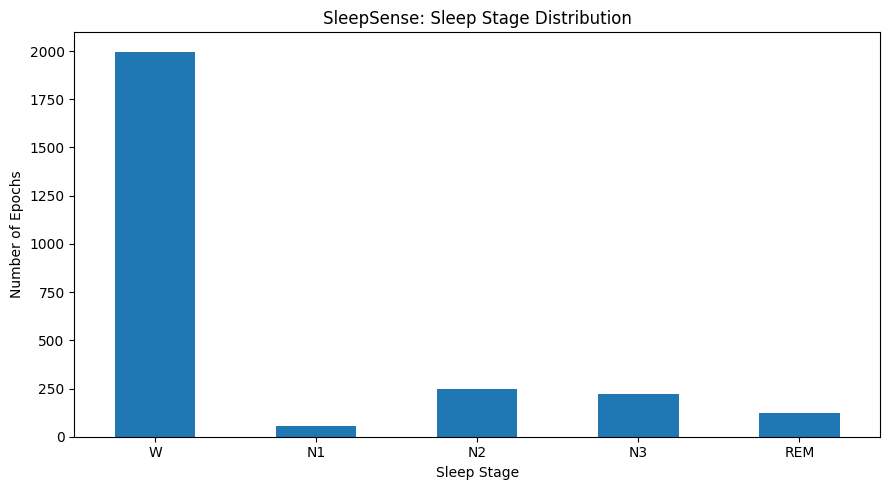

In [23]:
import matplotlib.pyplot as plt
import pandas as pd

stage_counts = pd.Series(y).value_counts()

stage_counts = stage_counts.reindex(
    ["W", "N1", "N2", "N3", "REM"],
    fill_value=0
)

stage_counts.plot(
    kind="bar",
    figsize=(9, 5),
    xlabel="Sleep Stage",
    ylabel="Number of Epochs",
    title="SleepSense: Sleep Stage Distribution"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
X = epochs.get_data()
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("Number of EEG epochs:", X.shape[0])
print("Number of EEG channels:", X.shape[1])
print("Samples per epoch:", X.shape[2])

X shape: (2650, 2, 3000)
y shape: (2650,)
Number of EEG epochs: 2650
Number of EEG channels: 2
Samples per epoch: 3000


# EEG Feature **Extraction**

In [25]:
import numpy as np
import pandas as pd

from scipy.signal import welch

In [26]:
def extract_time_features(signal):              #Define feature extraction functions
    signal = np.asarray(signal)

    activity = np.var(signal)

    first_derivative = np.diff(signal)
    second_derivative = np.diff(first_derivative)

    mobility = (
        np.sqrt(np.var(first_derivative) / activity)
        if activity > 0 else 0
    )

    complexity = (
        np.sqrt(np.var(second_derivative) /
                np.var(first_derivative)) / mobility
        if np.var(first_derivative) > 0 and mobility > 0
        else 0
    )

    return {
        "mean": np.mean(signal),
        "std": np.std(signal),
        "rms": np.sqrt(np.mean(signal ** 2)),
        "hjorth_activity": activity,
        "hjorth_mobility": mobility,
        "hjorth_complexity": complexity
    }

In [27]:
#Extract frequency-domain features
def extract_frequency_features(signal, sfreq):

    frequencies, psd = welch(
        signal,
        fs=sfreq,
        nperseg=min(len(signal), int(4 * sfreq))
    )

    bands = {
        "delta": (0.5, 4),
        "theta": (4, 8),
        "alpha": (8, 13),
        "sigma": (11, 16),
        "beta": (13, 30)
    }

    total_power = np.trapezoid(
        psd[(frequencies >= 0.5) & (frequencies <= 35)],
        frequencies[(frequencies >= 0.5) & (frequencies <= 35)]
    )

    features = {}

    for band, (low, high) in bands.items():

        mask = (frequencies >= low) & (frequencies <= high)

        power = np.trapezoid(
            psd[mask],
            frequencies[mask]
        ) if np.sum(mask) >= 2 else 0

        features[f"{band}_power"] = power

        features[f"{band}_relative_power"] = (
            power / total_power if total_power > 0 else 0
        )

    return features

In [28]:
#Extract features from every epoch
features_list = []

sfreq = filtered_eeg.info["sfreq"]
channel_names = epochs.ch_names

for epoch_index, epoch in enumerate(X):

    epoch_features = {}

    for channel_index, channel_name in enumerate(channel_names):

        signal = epoch[channel_index]

        time_features = extract_time_features(signal)
        frequency_features = extract_frequency_features(
            signal, sfreq
        )

        for name, value in time_features.items():
            epoch_features[f"{channel_name}_{name}"] = value

        for name, value in frequency_features.items():
            epoch_features[f"{channel_name}_{name}"] = value

    epoch_features["sleep_stage"] = y[epoch_index]

    features_list.append(epoch_features)

features_df = pd.DataFrame(features_list)

print("Feature extraction completed!")
print("Dataset shape:", features_df.shape)

display(features_df.head())

Feature extraction completed!
Dataset shape: (2650, 33)


,EEG Fpz-Cz_mean,EEG Fpz-Cz_std,EEG Fpz-Cz_rms,EEG Fpz-Cz_hjorth_activity,EEG Fpz-Cz_hjorth_mobility,EEG Fpz-Cz_hjorth_complexity,EEG Fpz-Cz_delta_power,EEG Fpz-Cz_delta_relative_power,EEG Fpz-Cz_theta_power,EEG Fpz-Cz_theta_relative_power,...,EEG Pz-Oz_delta_relative_power,EEG Pz-Oz_theta_power,EEG Pz-Oz_theta_relative_power,EEG Pz-Oz_alpha_power,EEG Pz-Oz_alpha_relative_power,EEG Pz-Oz_sigma_power,EEG Pz-Oz_sigma_relative_power,EEG Pz-Oz_beta_power,EEG Pz-Oz_beta_relative_power,sleep_stage
0,7.677320e-08,0.000036,0.000036,1.299930e-09,0.200366,6.108692,6.835205e-10,0.853724,9.437714e-11,0.117878,...,0.679991,4.884113e-12,0.134649,3.253217e-12,0.089687,2.094702e-12,0.057749,2.863771e-12,0.078951,W
1,-6.469066e-07,0.000026,0.000026,6.654303e-10,0.393699,3.664441,4.029480e-10,0.810147,4.376367e-11,0.087989,...,0.401342,5.679934e-12,0.103916,7.241140e-12,0.132479,6.031485e-12,0.110348,1.528662e-11,0.279674,W
2,8.259596e-07,0.000031,0.000031,9.699986e-10,0.258863,5.597541,5.225989e-10,0.899825,2.271802e-11,0.039117,...,0.320120,5.234577e-12,0.086165,3.089535e-11,0.508558,2.902779e-12,0.047782,4.482796e-12,0.073790,W
3,-5.141783e-07,0.000018,0.000018,3.073842e-10,0.316290,4.090785,1.886731e-10,0.813741,2.051944e-11,0.088500,...,0.231959,1.280109e-11,0.152408,4.730373e-11,0.563190,1.973719e-12,0.023499,3.963850e-12,0.047193,W
4,-1.102670e-07,0.000017,0.000017,2.838617e-10,0.340875,3.508630,1.836531e-10,0.752217,4.068264e-11,0.166630,...,0.237164,2.393124e-11,0.268521,3.964185e-11,0.444802,2.576586e-12,0.028911,4.032750e-12,0.045250,W


In [29]:
#Inspect the feature dataset
print("Dataset information:")
features_df.info()

print("\nMissing values:")
print(features_df.isnull().sum().sum())

print("\nSleep-stage distribution:")
print(features_df["sleep_stage"].value_counts())

print("\nFeature statistics:")
display(features_df.describe().T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2650 entries, 0 to 2649
Data columns (total 33 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   EEG Fpz-Cz_mean                  2650 non-null   float64
 1   EEG Fpz-Cz_std                   2650 non-null   float64
 2   EEG Fpz-Cz_rms                   2650 non-null   float64
 3   EEG Fpz-Cz_hjorth_activity       2650 non-null   float64
 4   EEG Fpz-Cz_hjorth_mobility       2650 non-null   float64
 5   EEG Fpz-Cz_hjorth_complexity     2650 non-null   float64
 6   EEG Fpz-Cz_delta_power           2650 non-null   float64
 7   EEG Fpz-Cz_delta_relative_power  2650 non-null   float64
 8   EEG Fpz-Cz_theta_power           2650 non-null   float64
 9   EEG Fpz-Cz_theta_relative_power  2650 non-null   float64
 10  EEG Fpz-Cz_alpha_power           2650 non-null   float64
 11  EEG Fpz-Cz_alpha_relative_power  2650 non-null   float64
 12 

,count,mean,std,min,25%,50%,75%,max
EEG Fpz-Cz_mean,2650.0,-2.772172e-10,3.623793e-07,-1.877948e-06,-1.892450e-07,1.285051e-09,2.012122e-07,1.653649e-06
EEG Fpz-Cz_std,2650.0,2.436054e-05,7.799684e-06,7.141215e-06,1.969842e-05,2.472283e-05,2.938710e-05,5.627757e-05
EEG Fpz-Cz_rms,2650.0,2.436297e-05,7.800518e-06,7.142418e-06,1.969880e-05,2.472403e-05,2.938954e-05,5.628303e-05
EEG Fpz-Cz_hjorth_activity,2650.0,6.542482e-10,3.894421e-10,5.099695e-11,3.880279e-10,6.112183e-10,8.636016e-10,3.167165e-09
EEG Fpz-Cz_hjorth_mobility,2650.0,2.851906e-01,7.804826e-02,9.927791e-02,2.421307e-01,2.826804e-01,3.267177e-01,6.736388e-01
EEG Fpz-Cz_hjorth_complexity,2650.0,4.542008e+00,9.935870e-01,1.968893e+00,3.881253e+00,4.528335e+00,5.150416e+00,1.032933e+01
EEG Fpz-Cz_delta_power,2650.0,4.019162e-10,2.591017e-10,1.806423e-11,2.347822e-10,3.697328e-10,5.127091e-10,1.790808e-09
EEG Fpz-Cz_delta_relative_power,2650.0,8.353103e-01,8.845815e-02,2.253106e-01,8.142448e-01,8.544180e-01,8.839246e-01,9.715375e-01
EEG Fpz-Cz_theta_power,2650.0,3.662754e-11,1.653042e-11,7.880373e-12,2.517577e-11,3.456254e-11,4.558276e-11,1.410321e-10
EEG Fpz-Cz_theta_relative_power,2650.0,9.908382e-02,6.014940e-02,1.995371e-02,6.667065e-02,8.347172e-02,1.111714e-01,6.680294e-01


In [30]:
os.makedirs("/content/sleepsense/processed", exist_ok=True)

features_path = "/content/sleepsense/processed/sleep_features.csv"

features_df.to_csv(features_path, index=False)

print("Saved:", features_path)

Saved: /content/sleepsense/processed/sleep_features.csv


In [31]:
from google.colab import files

files.download(features_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Train the first classifier

In [32]:
#Prepare features and labels
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score
)

# Separate features and target
X_ml = features_df.drop(columns=["sleep_stage"])
y_ml = features_df["sleep_stage"]

# Convert sleep-stage labels into numeric labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_ml)

print("Classes:", label_encoder.classes_)
print("Feature count:", X_ml.shape[1])
print("Number of epochs:", X_ml.shape[0])

Classes: [np.str_('N1') np.str_('N2') np.str_('N3') np.str_('REM') np.str_('W')]
Feature count: 32
Number of epochs: 2650


In [33]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_ml,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2120
Testing samples: 530


In [34]:
#Train the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [35]:
#Generate predictions
y_pred = rf_model.predict(X_test)

print("Predictions generated!")
print("First 15 predictions:",
      label_encoder.inverse_transform(y_pred[:15]))

Predictions generated!
First 15 predictions: [np.str_('N3') np.str_('W') np.str_('W') np.str_('W') np.str_('W')
 np.str_('REM') np.str_('N3') np.str_('W') np.str_('W') np.str_('W')
 np.str_('W') np.str_('W') np.str_('W') np.str_('W') np.str_('N2')]


In [36]:
#Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)

balanced_acc = balanced_accuracy_score(
    y_test, y_pred
)

macro_f1 = f1_score(
    y_test, y_pred,
    average="macro"
)

print("MODEL PERFORMANCE")
print("------------------")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")
print(f"Macro F1 Score:    {macro_f1:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

MODEL PERFORMANCE
------------------
Accuracy:          0.9660
Balanced Accuracy: 0.8004
Macro F1 Score:    0.8081

Classification Report:

              precision    recall  f1-score   support

          N1       0.50      0.25      0.33        12
          N2       0.89      0.96      0.92        50
          N3       0.98      0.95      0.97        44
         REM       0.81      0.84      0.82        25
           W       0.99      1.00      0.99       399

    accuracy                           0.97       530
   macro avg       0.83      0.80      0.81       530
weighted avg       0.96      0.97      0.96       530



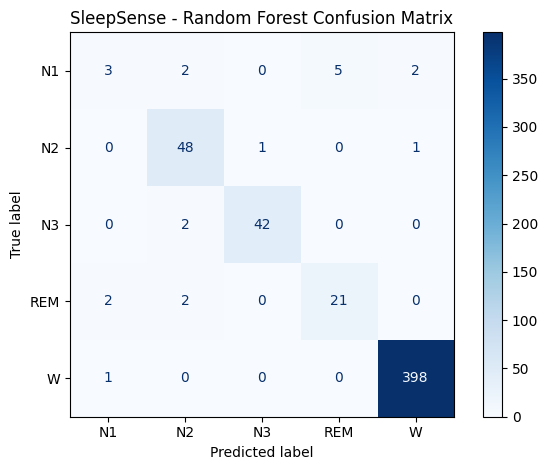

In [37]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("SleepSense - Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [38]:
#Understand which EEG features matter
importance_df = pd.DataFrame({
    "Feature": X_ml.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
31,EEG Pz-Oz_beta_relative_power,0.099344
27,EEG Pz-Oz_alpha_relative_power,0.069296
20,EEG Pz-Oz_hjorth_mobility,0.065890
6,EEG Fpz-Cz_delta_power,0.064067
29,EEG Pz-Oz_sigma_relative_power,0.061573
15,EEG Fpz-Cz_beta_relative_power,0.052716
14,EEG Fpz-Cz_beta_power,0.051244
3,EEG Fpz-Cz_hjorth_activity,0.046425
2,EEG Fpz-Cz_rms,0.042625
1,EEG Fpz-Cz_std,0.039833


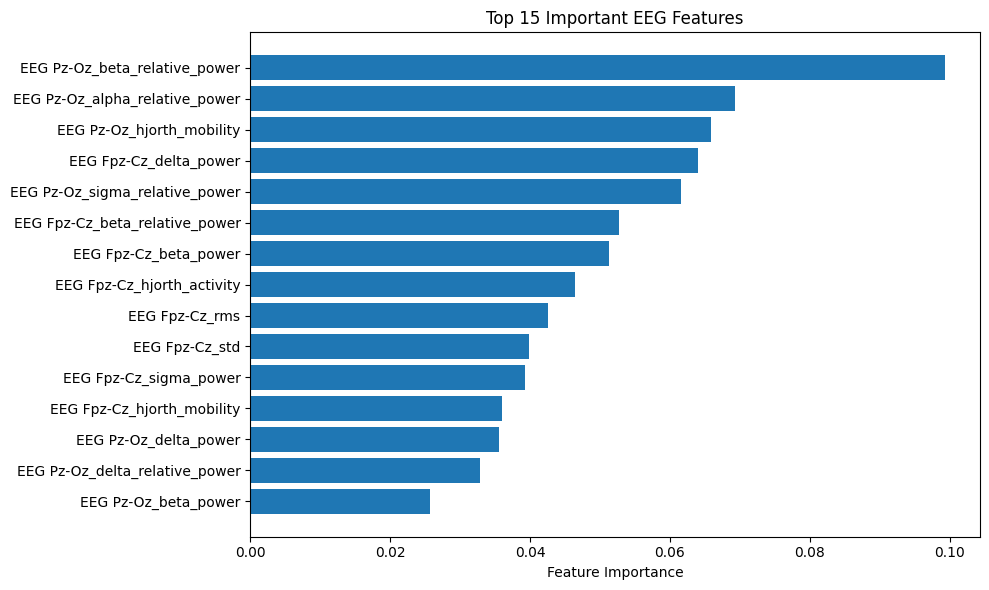

In [39]:
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Important EEG Features")
plt.tight_layout()
plt.show()

In [40]:
#Save the trained model
import joblib

MODEL_PATH = "/content/sleepsense/random_forest_model.pkl"

joblib.dump(
    {
        "model": rf_model,
        "label_encoder": label_encoder,
        "feature_columns": list(X_ml.columns)
    },
    MODEL_PATH
)

print("Model saved:", MODEL_PATH)

Model saved: /content/sleepsense/random_forest_model.pkl


In [41]:
from google.colab import files

files.download(MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>